# USD/CAD (FRED: DEXCAUS)

**Datos:** DEXCAUS (dólares canadienses por 1 dólar estadounidense, tipo de cambio diario, fuente FRED), nov-2025 → nov-2026. https://fred.stlouisfed.org/series/DEXCAUS

$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t \;\Rightarrow\; r_t=\ln\frac{S_t}{S_{t-1}}\ \overset{iid}{\sim}\ N\!\big((\mu-\tfrac{\sigma^2}{2})\Delta t,\ \sigma^2\Delta t\big)$$

| # | Condición | Pruebas (H0 = se cumple) |
|---|---|---|
| C1 | Normalidad de $r_t$ | Jarque-Bera, Shapiro-Wilk (+ D'Agostino, QQ-plot) |
| C2 | Independencia | Ljung-Box (10 rezagos), test de rachas, ACF |
| C3 | Varianza constante | Ljung-Box sobre $r_t^2$, ARCH-LM |
| C4 | Parámetros estables | t-test, Levene, KS entre mitades |
| C5 | Ajuste global | Simulación Monte Carlo |

Las secciones 10 y 11 añaden: (10) pronóstico simulado sobre la muestra con 10.000 simulaciones y métricas de ajuste y precisión; (11) comparación de Black-Scholes, Monte Carlo, árboles binomiales y diferencias finitas explícitas para T = 1, 1/2, 1/3 y 1/4.

**Decisión:** compatible con GBM si ninguna de las 9 pruebas rechaza H0 a α = 5 % (criterio estricto) o a α/9 (criterio Bonferroni, que corrige por pruebas múltiples).

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": .3})
np.random.seed(42)

CSV = "DEXCAUS.csv"
if not os.path.exists(CSV):
    CSV = "/mnt/user-data/uploads/DEXCAUS.csv"

ALPHA = 0.05
PPY = 252                   # días hábiles por año (diario)
dt = 1 / PPY

## 1. Carga de datos

In [4]:
df = pd.read_csv(CSV, parse_dates=["observation_date"]).set_index("observation_date").sort_index()
price_col = "DEXCAUS"
df[price_col] = pd.to_numeric(df[price_col], errors="coerce")   # FRED marca feriados con celdas vacías
print(f"Filas: {len(df)} | feriados/sin dato: {df[price_col].isna().sum()}")
S = df[price_col].dropna()
S.index.name = "Date"

r = np.log(S / S.shift(1)).dropna(); r.name = "log_return"
n = len(r)
print(f"Observaciones de la serie: {len(S)} | Log-retornos: {n} | {S.index[0].date()} → {S.index[-1].date()}")
assert len(S) >= 250, "Se requieren al menos 250 observaciones"
df.tail(3)

Filas: 261 | feriados/sin dato: 11
Observaciones de la serie: 250 | Log-retornos: 249 | 2025-11-07 → 2026-11-06


,DEXCAUS
observation_date,
2026-11-04,1.3973
2026-11-05,1.3980
2026-11-06,1.4106


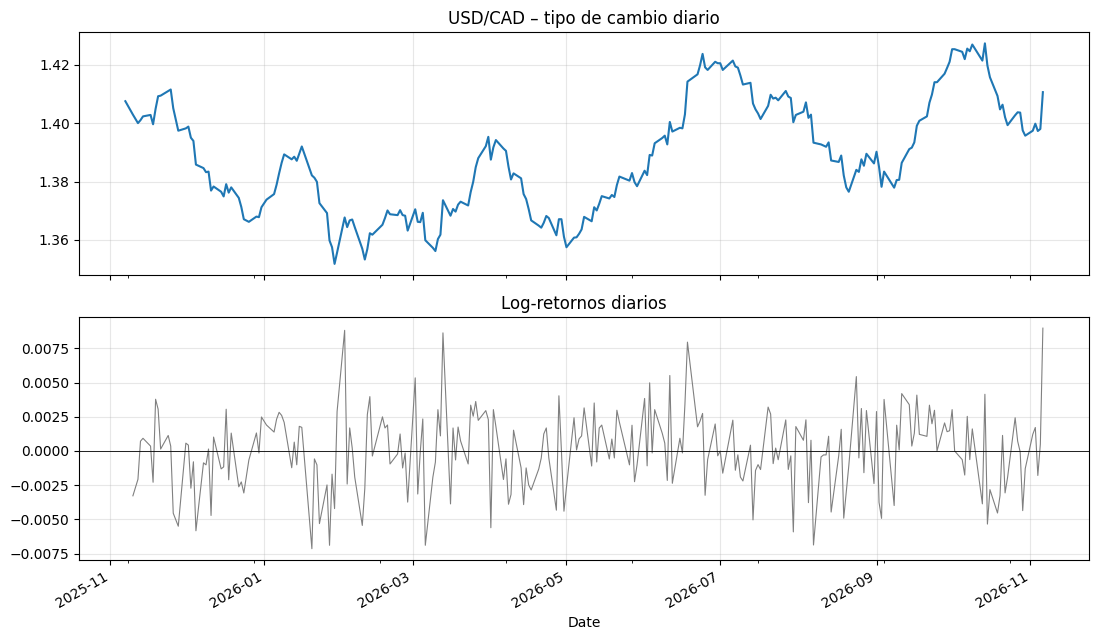

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
S.plot(ax=ax[0]); ax[0].set_title(f"USD/CAD – tipo de cambio diario")
r.plot(ax=ax[1], color="gray", lw=.8); ax[1].axhline(0, color="k", lw=.6); ax[1].set_title("Log-retornos diarios")
plt.tight_layout(); plt.show()

## 2. Funciones de prueba
(Implementadas con `numpy`/`scipy`, sin depender de `statsmodels`.)

In [6]:
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x); den = np.sum(x**2)
    return np.array([np.sum(x[k:] * x[:len(x)-k]) / den for k in range(1, nlags + 1)])

def ljung_box(x, lags):
    x = np.asarray(x); m = len(x); rho = acf(x, lags)
    Q = m * (m + 2) * np.sum(rho**2 / (m - np.arange(1, lags + 1)))
    return Q, stats.chi2.sf(Q, lags)

def runs_test(x):
    s = np.asarray(x) > np.median(x); n1, n2 = s.sum(), (~s).sum()
    runs = 1 + np.sum(s[1:] != s[:-1])
    mu_r = 2*n1*n2/(n1+n2) + 1
    var_r = 2*n1*n2*(2*n1*n2-n1-n2) / ((n1+n2)**2 * (n1+n2-1))
    z = (runs - mu_r) / np.sqrt(var_r)
    return z, 2 * stats.norm.sf(abs(z))

def arch_lm(x, q=5):
    e2 = (np.asarray(x) - np.mean(x))**2; y = e2[q:]
    X = np.column_stack([np.ones(len(y))] + [e2[q-i: len(e2)-i] for i in range(1, q+1)])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    R2 = 1 - np.sum((y - X@b)**2) / np.sum((y - y.mean())**2)
    LM = len(y) * R2
    return LM, stats.chi2.sf(LM, q)

def battery(x):
    x = np.asarray(x); h = len(x) // 2
    return {
        "C1 Jarque-Bera":        stats.jarque_bera(x)[1],
        "C1 Shapiro-Wilk":       stats.shapiro(x)[1],
        "C2 Ljung-Box r (10)":   ljung_box(x, 10)[1],
        "C2 Test de rachas":     runs_test(x)[1],
        "C3 Ljung-Box r² (10)":  ljung_box(x**2, 10)[1],
        "C3 ARCH-LM (5)":        arch_lm(x, 5)[1],
        "C4 t-test medias":      stats.ttest_ind(x[:h], x[h:], equal_var=False)[1],
        "C4 Levene varianzas":   stats.levene(x[:h], x[h:])[1],
        "C4 KS 2 muestras":      stats.ks_2samp(x[:h], x[h:])[1],
    }

## 3. Estimación de parámetros

$$\hat\sigma=\frac{s_r}{\sqrt{\Delta t}},\qquad \hat\mu=\frac{\bar r}{\Delta t}+\frac{\hat\sigma^2}{2}$$

In [7]:
r_bar, s_r = r.mean(), r.std(ddof=1)
sigma_hat = s_r / np.sqrt(dt)
mu_hat = r_bar / dt + 0.5 * sigma_hat**2
se_mu = s_r / np.sqrt(n) / dt
print(f"Media diaria log-ret : {r_bar:.6f}")
print(f"Desv. diaria log-ret : {s_r:.6f}")
print(f"σ̂ anualizada          : {sigma_hat:.2%}")
print(f"μ̂ anualizado          : {mu_hat:.2%}   (error estándar de r̄ anualizado ≈ {se_mu:.2%})")

Media diaria log-ret : 0.000009
Desv. diaria log-ret : 0.002838
σ̂ anualizada          : 4.50%
μ̂ anualizado          : 0.32%   (error estándar de r̄ anualizado ≈ 4.53%)


## 4. C1 – Normalidad

Asimetría = 0.008 | Curtosis en exceso = 0.423   (normal: 0 y 0)
Jarque-Bera        : stat=1.860  p=0.3946
Shapiro-Wilk       : stat=0.9856  p=0.0130
D'Agostino-Pearson : stat=1.984  p=0.3708


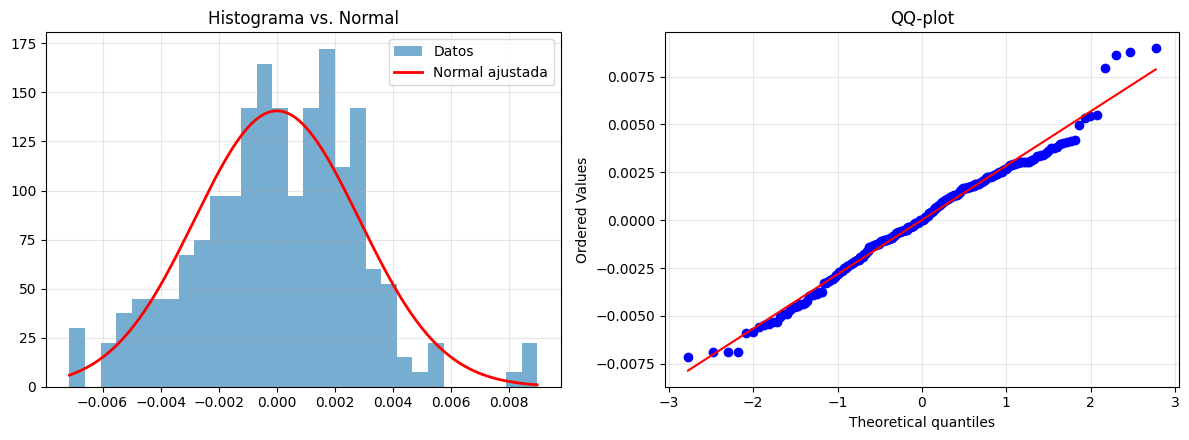


Observaciones más extremas (|z| > 3):


,log_ret,z
Date,,
2026-02-02,0.0088,3.1026
2026-03-13,0.0086,3.0374
2026-11-06,0.0090,3.1589


In [8]:
print(f"Asimetría = {stats.skew(r):.3f} | Curtosis en exceso = {stats.kurtosis(r):.3f}   (normal: 0 y 0)")
print(f"Jarque-Bera        : stat={stats.jarque_bera(r)[0]:.3f}  p={stats.jarque_bera(r)[1]:.4f}")
print(f"Shapiro-Wilk       : stat={stats.shapiro(r)[0]:.4f}  p={stats.shapiro(r)[1]:.4f}")
print(f"D'Agostino-Pearson : stat={stats.normaltest(r)[0]:.3f}  p={stats.normaltest(r)[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(r, bins=30, density=True, alpha=.6, label="Datos")
x = np.linspace(r.min(), r.max(), 400)
ax[0].plot(x, stats.norm.pdf(x, r_bar, s_r), "r", lw=2, label="Normal ajustada")
ax[0].set_title("Histograma vs. Normal"); ax[0].legend()
stats.probplot(r, dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot")
plt.tight_layout(); plt.show()

z = (r - r_bar) / s_r
print("\nObservaciones más extremas (|z| > 3):")
display(pd.DataFrame({"log_ret": r[z.abs() > 3], "z": z[z.abs() > 3]}).round(4))

## 5. C2 – Independencia  |  C3 – Varianza constante

Ljung-Box r   (lags= 5) p = 0.1137
Ljung-Box r   (lags=10) p = 0.3296
Ljung-Box r   (lags=20) p = 0.1406
Test de rachas           p = 0.8507
Ljung-Box r²  (lags= 5) p = 0.1282
Ljung-Box r²  (lags=10) p = 0.1109
Ljung-Box r²  (lags=20) p = 0.2980
ARCH-LM (q=5)            p = 0.0752


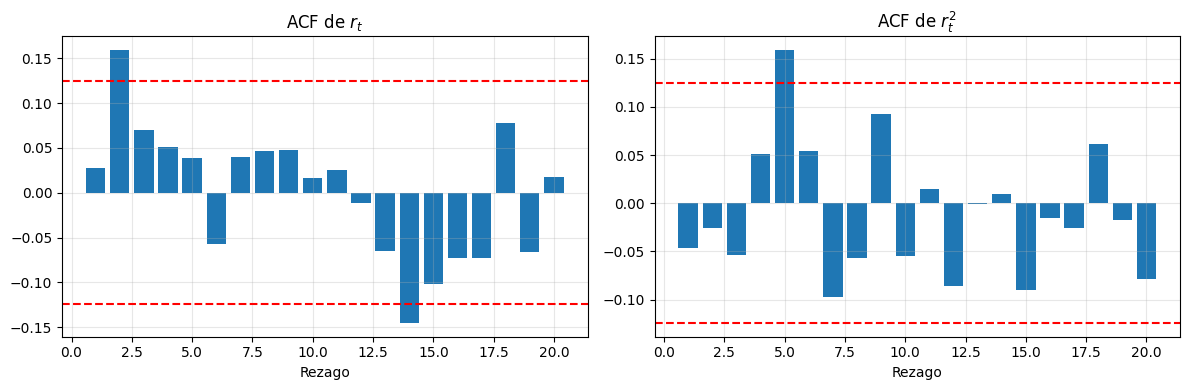

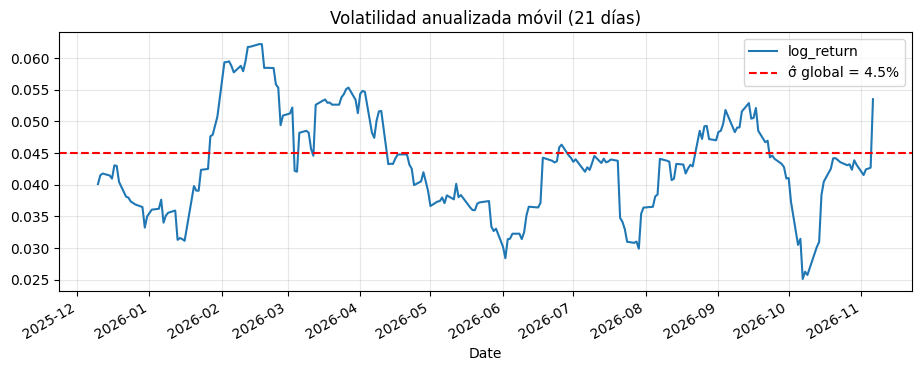

In [9]:
conf = 1.96 / np.sqrt(n)
for h in (5, 10, 20):
    print(f"Ljung-Box r   (lags={h:2d}) p = {ljung_box(r, h)[1]:.4f}")
print(f"Test de rachas           p = {runs_test(r)[1]:.4f}")
for h in (5, 10, 20):
    print(f"Ljung-Box r²  (lags={h:2d}) p = {ljung_box(r**2, h)[1]:.4f}")
print(f"ARCH-LM (q=5)            p = {arch_lm(r, 5)[1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, y, t in zip(ax, (r, r**2), ("ACF de $r_t$", "ACF de $r_t^2$")):
    a.bar(range(1, 21), acf(y, 20)); a.set_title(t); a.set_xlabel("Rezago")
    a.axhline(conf, color="r", ls="--"); a.axhline(-conf, color="r", ls="--")
plt.tight_layout(); plt.show()

w = 21   # ≈ un mes
ax = (r.rolling(w).std() / np.sqrt(dt)).plot(figsize=(11, 3.8), title=f"Volatilidad anualizada móvil ({w} días)")
ax.axhline(sigma_hat, color="r", ls="--", label=f"σ̂ global = {sigma_hat:.1%}"); ax.legend(); plt.show()

## 6. C4 – Estabilidad de parámetros

In [10]:
h = n // 2; r1, r2 = r.iloc[:h], r.iloc[h:]
print(f"Mitad 1 ({r1.index[0].date()} → {r1.index[-1].date()}): media anual={r1.mean()/dt:.3f}  vol anual={r1.std()/np.sqrt(dt):.3f}")
print(f"Mitad 2 ({r2.index[0].date()} → {r2.index[-1].date()}): media anual={r2.mean()/dt:.3f}  vol anual={r2.std()/np.sqrt(dt):.3f}")
print(f"t-test medias  p = {stats.ttest_ind(r1, r2, equal_var=False)[1]:.4f}")
print(f"Levene         p = {stats.levene(r1, r2)[1]:.4f}")
print(f"KS 2 muestras  p = {stats.ks_2samp(r1, r2)[1]:.4f}")

Mitad 1 (2025-11-10 → 2026-05-08): media anual=-0.058  vol anual=0.046
Mitad 2 (2026-05-11 → 2026-11-06): media anual=0.062  vol anual=0.044
t-test medias  p = 0.1863
Levene         p = 0.5869
KS 2 muestras  p = 0.5262


## 7. C5 – Simulación Monte Carlo vs. trayectoria real

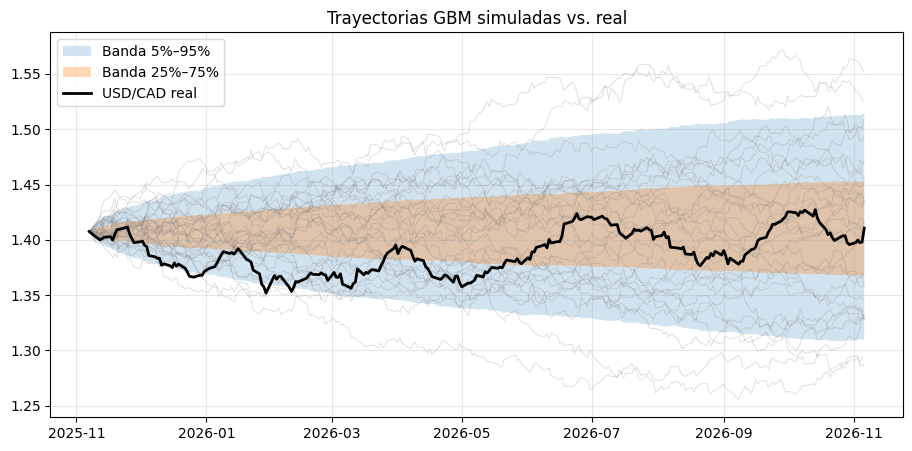

Percentil del precio final real en la simulación : 50.4%
% de días con precio real dentro de banda 5–95%: 94.8%


In [11]:
N_PATHS = 5000
Z = np.random.standard_normal((N_PATHS, n))
inc = (mu_hat - 0.5*sigma_hat**2)*dt + sigma_hat*np.sqrt(dt)*Z
paths = S.iloc[0] * np.exp(np.hstack([np.zeros((N_PATHS, 1)), np.cumsum(inc, axis=1)]))
q = np.percentile(paths, [5, 25, 50, 75, 95], axis=0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(S.index, paths[:30].T, color="gray", alpha=.25, lw=.7)
ax.fill_between(S.index, q[0], q[4], alpha=.2, label="Banda 5%–95%")
ax.fill_between(S.index, q[1], q[3], alpha=.3, label="Banda 25%–75%")
ax.plot(S.index, S.values, "k", lw=2, label="USD/CAD real"); ax.legend(); ax.set_title("Trayectorias GBM simuladas vs. real")
plt.show()

print(f"Percentil del precio final real en la simulación : {(paths[:, -1] < S.iloc[-1]).mean():.1%}")
print(f"% de días con precio real dentro de banda 5–95%: {np.mean((S.values >= q[0]) & (S.values <= q[4])):.1%}")

## 8. Robustez: ¿el resultado depende del subperiodo?

In [12]:
rows = []
for label, sub in [("Todo el periodo", r),
                   ("Primera mitad", r.iloc[:n // 2]),
                   ("Segunda mitad", r.iloc[n // 2:])]:
    if len(sub) >= 50:
        p = battery(sub); rows.append({"Ventana": label, "N": len(sub),
            **{k: round(v, 4) for k, v in p.items()},
            "Rechazos 5%": sum(v < ALPHA for v in p.values()),
            "Rechazos Bonf.": sum(v < ALPHA/9 for v in p.values())})
robust = pd.DataFrame(rows).set_index("Ventana")
robust.T

Ventana,Todo el periodo,Primera mitad,Segunda mitad
N,249.0000,124.0000,125.0000
C1 Jarque-Bera,0.3946,0.6022,0.6729
C1 Shapiro-Wilk,0.0130,0.0710,0.4877
C2 Ljung-Box r (10),0.3296,0.8206,0.2195
C2 Test de rachas,0.8507,0.1046,0.1266
C3 Ljung-Box r² (10),0.1109,0.0215,0.9092
C3 ARCH-LM (5),0.0752,0.0994,0.9703
C4 t-test medias,0.1863,0.1224,0.8391
C4 Levene varianzas,0.5869,0.9587,0.3252
C4 KS 2 muestras,0.5262,0.3981,0.4794


## 9. Tabla final y conclusión

In [13]:
pv = battery(r)
final = pd.DataFrame({"Prueba": list(pv), "p-valor": [round(v, 4) for v in pv.values()]})
final["Resultado (α=5%)"] = np.where(final["p-valor"] < ALPHA, "❌ Se rechaza H0", "✅ No se rechaza H0")
final["Resultado (Bonferroni)"] = np.where(final["p-valor"] < ALPHA/len(final), "❌ Se rechaza H0", "✅ No se rechaza H0")
display(final)

rej = int((final["p-valor"] < ALPHA).sum()); rej_b = int((final["p-valor"] < ALPHA/len(final)).sum())
print("="*72)
print(f"Rechazos con α=5%: {rej}/9   |   con α corregido ({ALPHA/len(final):.4f}): {rej_b}/9")
if rej == 0:
    print(f"CONCLUSIÓN: ninguna prueba rechaza los supuestos del GBM. USD/CAD ({n} obs) es COMPATIBLE\n"
          f"con un GBM (σ̂={sigma_hat:.1%}, μ̂={mu_hat:.1%}).")
elif rej_b == 0:
    print(f"CONCLUSIÓN: {rej} prueba(s) rechazan al 5% pero ninguna con el umbral corregido.\n"
          f"USD/CAD es COMPATIBLE con un GBM bajo el criterio de Bonferroni (σ̂={sigma_hat:.1%}, μ̂={mu_hat:.1%}).")
else:
    failed = ", ".join(final.loc[final["p-valor"] < ALPHA/len(final), "Prueba"])
    print(f"CONCLUSIÓN: se rechazan supuestos incluso con el umbral corregido ({failed}).\n"
          f"No puede afirmarse que USD/CAD siga un GBM; el modelo es solo una aproximación.")

,Prueba,p-valor,Resultado (α=5%),Resultado (Bonferroni)
0,C1 Jarque-Bera,0.3946,✅ No se rechaza H0,✅ No se rechaza H0
1,C1 Shapiro-Wilk,0.0130,❌ Se rechaza H0,✅ No se rechaza H0
2,C2 Ljung-Box r (10),0.3296,✅ No se rechaza H0,✅ No se rechaza H0
3,C2 Test de rachas,0.8507,✅ No se rechaza H0,✅ No se rechaza H0
4,C3 Ljung-Box r² (10),0.1109,✅ No se rechaza H0,✅ No se rechaza H0
5,C3 ARCH-LM (5),0.0752,✅ No se rechaza H0,✅ No se rechaza H0
6,C4 t-test medias,0.1863,✅ No se rechaza H0,✅ No se rechaza H0
7,C4 Levene varianzas,0.5869,✅ No se rechaza H0,✅ No se rechaza H0
8,C4 KS 2 muestras,0.5262,✅ No se rechaza H0,✅ No se rechaza H0


Rechazos con α=5%: 1/9   |   con α corregido (0.0056): 0/9
CONCLUSIÓN: 1 prueba(s) rechazan al 5% pero ninguna con el umbral corregido.
USD/CAD es COMPATIBLE con un GBM bajo el criterio de Bonferroni (σ̂=4.5%, μ̂=0.3%).


## 10. Pronóstico simulado sobre la muestra (10.000 simulaciones)

Con los parámetros estimados ($\hat\mu$, $\hat\sigma$) se simulan **10.000 trayectorias GBM** sobre el *mismo periodo observado* y se compara el pronóstico con la serie real, de dos formas:

- **(a) Multi-paso:** las trayectorias parten del primer precio de la muestra y se comparan con toda la serie (es el pronóstico más exigente, porque los errores se acumulan).
- **(b) Un paso adelante:** en cada fecha $t$ se simula $S_t$ a partir del precio real $S_{t-1}$.

**Métricas de ajuste y precisión** (error $e_t = S_t^{obs} - \hat S_t$, con $\hat S_t$ = media de las simulaciones):

| Métrica | Qué mide |
|---|---|
| ME (sesgo), MAE, RMSE | error medio, absoluto y cuadrático |
| MAPE, sMAPE | error porcentual |
| $R^2$, correlación | ajuste de la trayectoria esperada a la serie |
| Theil U | RMSE relativo a un pronóstico ingenuo (U < 1 = mejora al ingenuo) |
| Cobertura 50 % / 95 %, ancho | calibración de los intervalos simulados |
| CRPS | precisión de la distribución completa (menor = mejor) |
| PIT + KS | si la serie real es una extracción plausible de la distribución simulada |

In [14]:
N_SIM = 10_000
rng = np.random.default_rng(2026)

S_obs = S.values.astype(float)
m_obs = len(S_obs)
drift_log = (mu_hat - 0.5 * sigma_hat**2) * dt      # media del log-retorno por periodo (= r̄)
vol_step  = sigma_hat * np.sqrt(dt)                  # desv. del log-retorno por periodo (= s_r)

# ---------- (a) Trayectorias multi-paso desde el primer precio ----------
Z_in = rng.standard_normal((N_SIM, n))
sim_ret = drift_log + vol_step * Z_in
sim_a = S_obs[0] * np.exp(np.hstack([np.zeros((N_SIM, 1)), np.cumsum(sim_ret, axis=1)]))   # (N_SIM, m_obs)

# ---------- (b) Un paso adelante ----------
Z_1 = rng.standard_normal((N_SIM, n))
sim_b = S_obs[:-1] * np.exp(drift_log + vol_step * Z_1)                                     # (N_SIM, n)

def point_metrics(y, yhat, y_naive):
    e = y - yhat
    return {
        "Sesgo ME (obs − pron.)": e.mean(),
        "MAE": np.abs(e).mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "MAPE (%)": 100 * np.mean(np.abs(e / y)),
        "sMAPE (%)": 100 * np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(yhat))),
        "R²": 1 - (e**2).sum() / ((y - y.mean())**2).sum(),
        "Correlación": np.corrcoef(y, yhat)[0, 1] if np.std(yhat) > 0 else np.nan,
        "Theil U (vs. ingenuo)": np.sqrt((e**2).mean()) / np.sqrt(((y - y_naive)**2).mean()),
    }

def prob_metrics(y, X):
    # X: (N_SIM, T) simulaciones; y: (T,) observado
    lo95, hi95 = np.percentile(X, [2.5, 97.5], axis=0)
    lo50, hi50 = np.percentile(X, [25, 75], axis=0)
    N = X.shape[0]
    Xs = np.sort(X, axis=0); i = np.arange(1, N + 1)[:, None]
    mean_abs_diff = (2 / N**2) * ((2 * i - N - 1) * Xs).sum(axis=0)       # E|X − X'|
    crps = np.mean(np.abs(X - y).mean(axis=0) - 0.5 * mean_abs_diff)
    pit = (X < y).mean(axis=0)
    return {
        "Cobertura IC 50 % (nominal 50 %)": np.mean((y >= lo50) & (y <= hi50)),
        "Cobertura IC 95 % (nominal 95 %)": np.mean((y >= lo95) & (y <= hi95)),
        "Ancho medio IC 95 %": np.mean(hi95 - lo95),
        "CRPS medio": crps,
        "KS uniformidad PIT (p-valor)": stats.kstest(pit, "uniform")[1],
    }, pit

y_a, f_a = S_obs[1:], sim_a[:, 1:].mean(axis=0)
y_b, f_b = S_obs[1:], sim_b.mean(axis=0)

pm_a = point_metrics(y_a, f_a, y_naive=np.full_like(y_a, S_obs[0]))     # ingenuo: S0 constante
pm_b = point_metrics(y_b, f_b, y_naive=S_obs[:-1])                      # ingenuo: paseo aleatorio S_{t-1}
pb_a, pit_a = prob_metrics(y_a, sim_a[:, 1:])
pb_b, pit_b = prob_metrics(y_b, sim_b)

met = pd.DataFrame({"(a) Multi-paso desde S₀": {**pm_a, **pb_a},
                    "(b) Un paso adelante":   {**pm_b, **pb_b}})
display(met.round(4))

,(a) Multi-paso desde S₀,(b) Un paso adelante
Sesgo ME (obs − pron.),-0.0212,-0.0000
MAE,0.0236,0.0031
RMSE,0.0279,0.0039
MAPE (%),1.7130,0.2236
sMAPE (%),1.6932,0.2235
R²,-1.1700,0.9568
Correlación,0.5824,0.9784
Theil U (vs. ingenuo),1.0329,1.0006
Cobertura IC 50 % (nominal 50 %),0.5622,0.5100
Cobertura IC 95 % (nominal 95 %),1.0000,0.9558


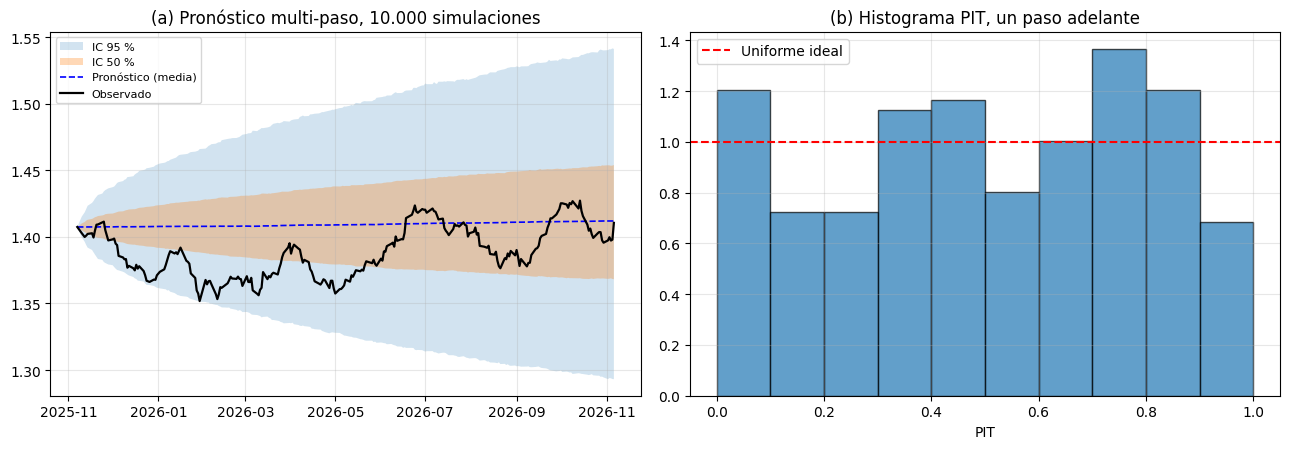

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
idx = S.index
lo, q25, med, q75, hi = np.percentile(sim_a, [2.5, 25, 50, 75, 97.5], axis=0)
ax[0].fill_between(idx, lo, hi, alpha=.2, label="IC 95 %")
ax[0].fill_between(idx, q25, q75, alpha=.3, label="IC 50 %")
ax[0].plot(idx, sim_a.mean(axis=0), "b--", lw=1.2, label="Pronóstico (media)")
ax[0].plot(idx, S_obs, "k", lw=1.6, label="Observado")
ax[0].set_title("(a) Pronóstico multi-paso, 10.000 simulaciones"); ax[0].legend(fontsize=8)

ax[1].hist(pit_b, bins=10, range=(0, 1), density=True, alpha=.7, edgecolor="k")
ax[1].axhline(1, color="r", ls="--", label="Uniforme ideal")
ax[1].set_title("(b) Histograma PIT, un paso adelante"); ax[1].set_xlabel("PIT"); ax[1].legend()
plt.tight_layout(); plt.show()

### Bondad de ajuste de la distribución: estadísticos de los retornos

Se compara cada estadístico de los log-retornos **observados** con su distribución en las 10.000 trayectorias simuladas. El *p-valor MC* (bilateral) indica si el dato real es una extracción plausible del modelo; un valor < 0,05 sería una señal de desajuste.

In [16]:
fns = {
    "media":             lambda x: x.mean(axis=-1),
    "desv. estándar":    lambda x: x.std(axis=-1, ddof=1),
    "asimetría":         lambda x: stats.skew(x, axis=-1),
    "curtosis en exceso":lambda x: stats.kurtosis(x, axis=-1),
    "mínimo":            lambda x: x.min(axis=-1),
    "máximo":            lambda x: x.max(axis=-1),
    "retorno acumulado": lambda x: x.sum(axis=-1),
}
rows = []
for name, f in fns.items():
    obs_v, sim_v = f(r.values), f(sim_ret)
    p_mc = min(1.0, 2 * min((sim_v <= obs_v).mean(), (sim_v >= obs_v).mean()))
    rows.append({"Estadístico": name, "Observado": obs_v, "Sim. media": sim_v.mean(),
                 "Sim. 2,5 %": np.percentile(sim_v, 2.5), "Sim. 97,5 %": np.percentile(sim_v, 97.5), "p-valor MC": p_mc})
gof = pd.DataFrame(rows).set_index("Estadístico")
display(gof.round(5))

ks = stats.ks_2samp(r.values, sim_ret.ravel())
print(f"KS 2 muestras (retornos observados vs. simulados): D = {ks.statistic:.4f}, p = {ks.pvalue:.4f}")

,Observado,Sim. media,"Sim. 2,5 %","Sim. 97,5 %",p-valor MC
Estadístico,,,,,
media,0.00001,0.00001,-0.00034,0.00036,0.9958
desv. estándar,0.00284,0.00283,0.00258,0.00309,0.9776
asimetría,0.00762,0.00108,-0.29943,0.29848,0.9674
curtosis en exceso,0.42310,-0.02433,-0.50877,0.67072,0.1544
mínimo,-0.00714,-0.00797,-0.01053,-0.00614,0.4590
máximo,0.00897,0.00801,0.00619,0.01049,0.3566
retorno acumulado,0.00220,0.00219,-0.08477,0.09084,0.9958


KS 2 muestras (retornos observados vs. simulados): D = 0.0422, p = 0.7499


In [17]:
cov95_b = met.loc["Cobertura IC 95 % (nominal 95 %)", "(b) Un paso adelante"]
cov95_a = met.loc["Cobertura IC 95 % (nominal 95 %)", "(a) Multi-paso desde S₀"]
print(f"• Un paso adelante: RMSE = {met.loc['RMSE','(b) Un paso adelante']:.5f} CAD, "
      f"Theil U = {met.loc['Theil U (vs. ingenuo)','(b) Un paso adelante']:.3f}, cobertura IC 95 % = {cov95_b:.1%}.")
print(f"• Multi-paso:       RMSE = {met.loc['RMSE','(a) Multi-paso desde S₀']:.5f} CAD, "
      f"R² = {met.loc['R²','(a) Multi-paso desde S₀']:.3f}, cobertura IC 95 % = {cov95_a:.1%}.")
bad = gof.index[gof['p-valor MC'] < ALPHA].tolist()
print("• Estadísticos de los retornos con p-valor MC < 5 %:", bad if bad else "ninguno (el modelo reproduce los momentos observados).")

• Un paso adelante: RMSE = 0.00393 CAD, Theil U = 1.001, cobertura IC 95 % = 95.6%.
• Multi-paso:       RMSE = 0.02786 CAD, R² = -1.170, cobertura IC 95 % = 100.0%.
• Estadísticos de los retornos con p-valor MC < 5 %: ninguno (el modelo reproduce los momentos observados).


## 11. Valoración de opciones europeas: Black-Scholes vs. Monte Carlo vs. Árbol binomial vs. Diferencias finitas explícitas

Se valoran **call y put europeas** sobre USD/CAD (precio en CAD por 1 USD) con cuatro métodos, para vencimientos $T\in\{1,\tfrac12,\tfrac13,\tfrac14\}$ años.

**Strikes:** para cada $T$ se simulan **10.000 trayectorias fuera de muestra** desde el último precio observado, con el GBM estimado ($\hat\mu$, $\hat\sigma$), y se toman 5 strikes como los **percentiles 10, 25, 50, 75 y 90 de $S_T$** simulado.

**Métodos** (todos bajo medida neutral al riesgo, con deriva $r-q$ y la volatilidad $\hat\sigma$ estimada):

1. **Black-Scholes** (fórmula cerrada, con rendimiento continuo $q$ = Garman-Kohlhagen): es la referencia.
2. **Monte Carlo:** $S_T = S_0\exp[(r-q-\tfrac{\sigma^2}{2})T+\sigma\sqrt T\,Z]$ con 10.000 simulaciones y variables antitéticas; se reporta el error estándar.
3. **Árbol binomial CRR** con $N$ pasos.
4. **Diferencias finitas explícitas** sobre la EDP en $x=\ln S$: $V_\tau=\tfrac12\sigma^2V_{xx}+(r-q-\tfrac{\sigma^2}{2})V_x-rV$, con $\Delta t\le\Delta x^2/\sigma^2$ (condición de estabilidad).

> ⚠️ **Supuestos que no vienen de tus datos:** la tasa libre de riesgo `r_free` y el rendimiento `q_yield` (en divisas, la tasa del activo extranjero). Los valores por defecto son ilustrativos; ajústalos a las tasas vigentes de CAD/USD si los necesitas.

In [18]:
import time

# ---------------- Parámetros (ajustables) ----------------
r_free  = 0.04          # tasa libre de riesgo anual (SUPUESTO)
q_yield = 0.00          # 0 = Black-Scholes clásico; > 0 = Garman-Kohlhagen (tasa foránea)
T_LIST  = [1, 1/2, 1/3, 1/4]
PCTS    = [10, 25, 50, 75, 90]     # percentiles de S_T simulado -> strikes
N_BIN   = 1000                     # pasos del árbol binomial
NH_FD   = 300                      # nodos a cada lado de S0 en la malla de diferencias finitas
S0_last = float(S_obs[-1])
sig = sigma_hat

# ---------------- Métodos de valoración ----------------
def bs_price(S0, K, T, r, q, sig, kind):
    d1 = (np.log(S0 / K) + (r - q + 0.5 * sig**2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
    if kind == "call":
        return S0 * np.exp(-q * T) * stats.norm.cdf(d1) - K * np.exp(-r * T) * stats.norm.cdf(d2)
    return K * np.exp(-r * T) * stats.norm.cdf(-d2) - S0 * np.exp(-q * T) * stats.norm.cdf(-d1)

def mc_price(S0, K, T, r, q, sig, Zhalf, kind):
    # variables antitéticas: se usan Z y −Z; el error estándar se calcula sobre los promedios por pares
    def payoff(Z):
        ST = S0 * np.exp((r - q - 0.5 * sig**2) * T + sig * np.sqrt(T) * Z)
        return np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    pair = 0.5 * (payoff(Zhalf) + payoff(-Zhalf)) * np.exp(-r * T)
    return pair.mean(), pair.std(ddof=1) / np.sqrt(len(pair))

def binomial_crr(S0, K, T, r, q, sig, kind, N=1000):
    dt_ = T / N; u = np.exp(sig * np.sqrt(dt_)); d = 1 / u
    p = (np.exp((r - q) * dt_) - d) / (u - d); disc = np.exp(-r * dt_)
    assert 0 < p < 1
    j = np.arange(N + 1); ST = S0 * u**j * d**(N - j)
    V = np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    for _ in range(N):
        V = disc * (p * V[1:] + (1 - p) * V[:-1])
    return V[0]

def fd_explicit(S0, K, T, r, q, sig, kind, Nh=300, safety=0.9):
    nu = r - q - 0.5 * sig**2
    L = 6 * sig * np.sqrt(T) + abs(nu) * T                 # semiancho del dominio en log-precio
    dx = L / Nh
    Nt = int(np.ceil(T / (safety * dx**2 / sig**2))); dtau = T / Nt
    a = dtau * (0.5 * sig**2 / dx**2 - 0.5 * nu / dx)      # coef. de V_{j-1}
    b = 1 - dtau * (sig**2 / dx**2 + r)                    # coef. de V_j
    c = dtau * (0.5 * sig**2 / dx**2 + 0.5 * nu / dx)      # coef. de V_{j+1}
    assert min(a, b, c) >= 0, "Esquema explícito inestable: aumentar Nh o reducir dt"
    Sg = S0 * np.exp(dx * np.arange(-Nh, Nh + 1))          # S0 es un nodo exacto (índice Nh)
    V = np.maximum(Sg - K, 0.0) if kind == "call" else np.maximum(K - Sg, 0.0)
    for k in range(1, Nt + 1):
        tau = k * dtau
        Vn = np.empty_like(V)
        Vn[1:-1] = a * V[:-2] + b * V[1:-1] + c * V[2:]
        if kind == "call":
            Vn[0], Vn[-1] = 0.0, Sg[-1] * np.exp(-q * tau) - K * np.exp(-r * tau)
        else:
            Vn[0], Vn[-1] = K * np.exp(-r * tau) - Sg[0] * np.exp(-q * tau), 0.0
        V = Vn
    return V[Nh], Nt

# ---------------- Strikes desde trayectorias fuera de muestra ----------------
rng_oos = np.random.default_rng(7)
oos, strikes = {}, {}
for T in T_LIST:
    steps = int(round(T * PPY))
    Zo = rng_oos.standard_normal((N_SIM, steps))
    paths = S0_last * np.exp(np.cumsum(drift_log + vol_step * Zo, axis=1))
    oos[T] = paths
    strikes[T] = np.round(np.percentile(paths[:, -1], PCTS), 4)

print(f"S0 (último precio observado, {S.index[-1].date()}) = {S0_last:.4f} | σ̂ = {sig:.4%} | r = {r_free:.2%} | q = {q_yield:.2%}\n")
display(pd.DataFrame({f"T={T:.4g}": strikes[T] for T in T_LIST}, index=[f"P{p}" for p in PCTS]).T)

S0 (último precio observado, 2026-11-06) = 1.4106 | σ̂ = 4.5045% | r = 4.00% | q = 0.00%



,P10,P25,P50,P75,P90
T=1,1.3357,1.3711,1.4142,1.4570,1.4979
T=0.5,1.3558,1.3825,1.4124,1.4426,1.4691
T=0.3333,1.3654,1.3879,1.4121,1.4362,1.4597
T=0.25,1.3708,1.3900,1.4114,1.4332,1.4527


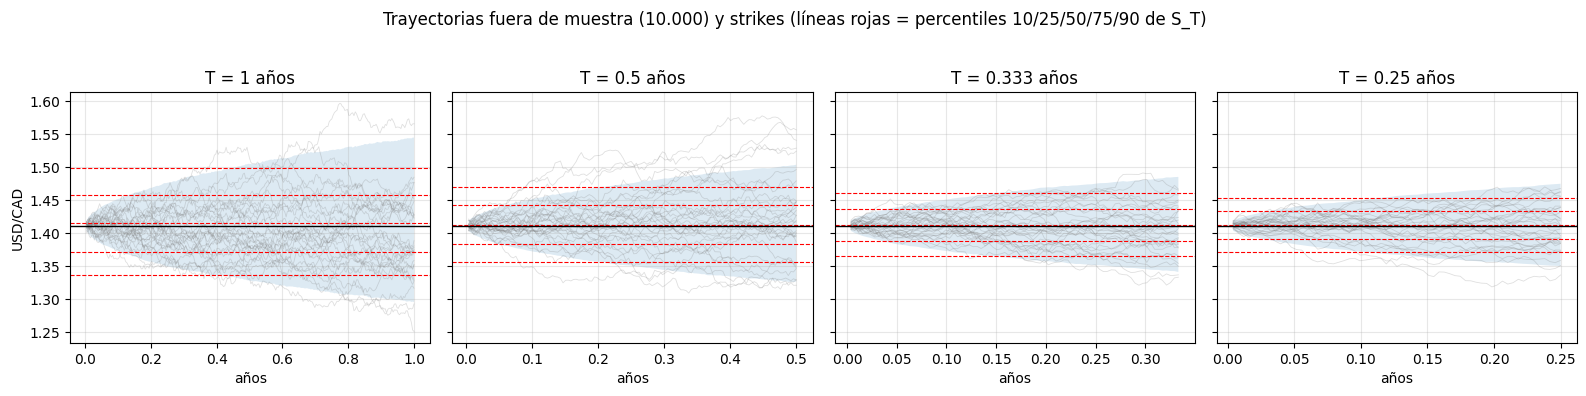

In [19]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, T in zip(axs, T_LIST):
    P = oos[T]; tt = np.arange(1, P.shape[1] + 1) / PPY
    ax.plot(tt, P[:30].T, color="gray", alpha=.25, lw=.6)
    ax.fill_between(tt, *np.percentile(P, [2.5, 97.5], axis=0), alpha=.15)
    for K in strikes[T]: ax.axhline(K, color="r", lw=.8, ls="--")
    ax.axhline(S0_last, color="k", lw=1); ax.set_title(f"T = {T:.3g} años"); ax.set_xlabel("años")
axs[0].set_ylabel("USD/CAD")
plt.suptitle("Trayectorias fuera de muestra (10.000) y strikes (líneas rojas = percentiles 10/25/50/75/90 de S_T)", y=1.03)
plt.tight_layout(); plt.show()

In [20]:
rng_mc = np.random.default_rng(123)
rows, timing = [], {"Black-Scholes": 0.0, "Monte Carlo": 0.0, "Árbol binomial": 0.0, "Dif. finitas": 0.0}
fd_steps = {}
for T in T_LIST:
    Zh = rng_mc.standard_normal(N_SIM // 2)                      # mismas Z para todos los strikes de un T
    for pct, K in zip(PCTS, strikes[T]):
        for kind in ("call", "put"):
            t0 = time.perf_counter(); bs = bs_price(S0_last, K, T, r_free, q_yield, sig, kind); timing["Black-Scholes"] += time.perf_counter() - t0
            t0 = time.perf_counter(); mc, se = mc_price(S0_last, K, T, r_free, q_yield, sig, Zh, kind); timing["Monte Carlo"] += time.perf_counter() - t0
            t0 = time.perf_counter(); bi = binomial_crr(S0_last, K, T, r_free, q_yield, sig, kind, N=N_BIN); timing["Árbol binomial"] += time.perf_counter() - t0
            t0 = time.perf_counter(); fd, nt = fd_explicit(S0_last, K, T, r_free, q_yield, sig, kind, Nh=NH_FD); timing["Dif. finitas"] += time.perf_counter() - t0
            fd_steps[T] = nt
            rows.append({"T": T, "Pctl": f"P{pct}", "K": K, "Tipo": kind, "BS": bs, "MC": mc, "EE MC": se, "Binomial": bi, "DF explícitas": fd,
                         "|MC−BS|": abs(mc - bs), "|Bin−BS|": abs(bi - bs), "|DF−BS|": abs(fd - bs)})
opt = pd.DataFrame(rows)
print(f"Pasos de tiempo en diferencias finitas por T (estabilidad): { {round(k,3): v for k, v in fd_steps.items()} }")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
display(opt.round(6))

Pasos de tiempo en diferencias finitas por T (estabilidad): {1: 2122, 0.5: 2288, 0.333: 2368, 0.25: 2417}


,T,Pctl,K,Tipo,BS,MC,EE MC,Binomial,DF explícitas,|MC−BS|,|Bin−BS|,|DF−BS|
0,1.000000,P10,1.3357,call,0.127666,0.127635,0.000056,0.127666,0.127667,0.000031,0.000000,0.000000
1,1.000000,P10,1.3357,put,0.000393,0.000358,0.000033,0.000392,0.000393,0.000035,0.000000,0.000000
2,1.000000,P25,1.3711,call,0.094986,0.094970,0.000107,0.094984,0.094987,0.000016,0.000003,0.000000
3,1.000000,P25,1.3711,put,0.001725,0.001705,0.000081,0.001722,0.001725,0.000020,0.000003,0.000000
4,1.000000,P50,1.4142,call,0.058941,0.059022,0.000200,0.058936,0.058940,0.000081,0.000005,0.000000
5,1.000000,P50,1.4142,put,0.007089,0.007167,0.000172,0.007084,0.007088,0.000078,0.000005,0.000001
6,1.000000,P75,1.4570,call,0.030977,0.031074,0.000279,0.030974,0.030975,0.000097,0.000003,0.000002
7,1.000000,P75,1.4570,put,0.020247,0.020341,0.000253,0.020244,0.020245,0.000093,0.000003,0.000003
8,1.000000,P90,1.4979,call,0.013815,0.013915,0.000247,0.013800,0.013810,0.000101,0.000015,0.000004
9,1.000000,P90,1.4979,put,0.042381,0.042478,0.000220,0.042366,0.042376,0.000097,0.000015,0.000005


### Resumen de precisión frente a Black-Scholes

In [21]:
summ = pd.DataFrame({
    "Monte Carlo":    opt["|MC−BS|"],
    "Árbol binomial": opt["|Bin−BS|"],
    "Dif. finitas":   opt["|DF−BS|"],
}).agg(["mean", "max"]).T
summ.columns = ["Error abs. medio", "Error abs. máximo"]
summ["RMSE"] = [np.sqrt(((opt["MC"] - opt["BS"])**2).mean()),
                np.sqrt(((opt["Binomial"] - opt["BS"])**2).mean()),
                np.sqrt(((opt["DF explícitas"] - opt["BS"])**2).mean())]
summ["Tiempo total (s)"] = [timing["Monte Carlo"], timing["Árbol binomial"], timing["Dif. finitas"]]
display(summ.applymap(lambda v: f"{v:.3e}") if hasattr(summ, "applymap") else summ)

inside = (np.abs(opt["MC"] - opt["BS"]) <= 1.96 * opt["EE MC"]).mean()
print(f"\nMonte Carlo: BS cae dentro de ±1,96·EE en {inside:.1%} de los casos (esperado ≈ 95 %).")
print(f"Tiempo de Black-Scholes (referencia): {timing['Black-Scholes']:.4f} s")

# Paridad put-call: C − P = S0·e^{-qT} − K·e^{-rT}
par = []
for (T, K), g in opt.groupby(["T", "K"]):
    c, p = g[g.Tipo == "call"].iloc[0], g[g.Tipo == "put"].iloc[0]
    th = S0_last * np.exp(-q_yield * T) - K * np.exp(-r_free * T)
    par.append({"BS": (c.BS - p.BS) - th, "MC": (c.MC - p.MC) - th, "Binomial": (c.Binomial - p.Binomial) - th, "DF": (c["DF explícitas"] - p["DF explícitas"]) - th})
par = pd.DataFrame(par).abs().max()
print("\nMáx. desviación de la paridad put-call (|C − P − teórico|):"); display(par.map(lambda v: f"{v:.2e}").to_frame("desviación"))

/tmp/ipykernel_2397/333544251.py:11: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  display(summ.applymap(lambda v: f"{v:.3e}") if hasattr(summ, "applymap") else summ)


,Error abs. medio,Error abs. máximo,RMSE,Tiempo total (s)
Monte Carlo,6.220e-05,1.335e-04,7.598e-05,1.239e-02
Árbol binomial,2.721e-06,1.508e-05,4.208e-06,2.589e-01
Dif. finitas,7.914e-07,4.994e-06,1.372e-06,1.084e+00



Monte Carlo: BS cae dentro de ±1,96·EE en 100.0% de los casos (esperado ≈ 95 %).
Tiempo de Black-Scholes (referencia): 0.0175 s

Máx. desviación de la paridad put-call (|C − P − teórico|):


,desviación
BS,3.05e-16
MC,1.17e-05
Binomial,1.42e-13
DF,5.52e-07


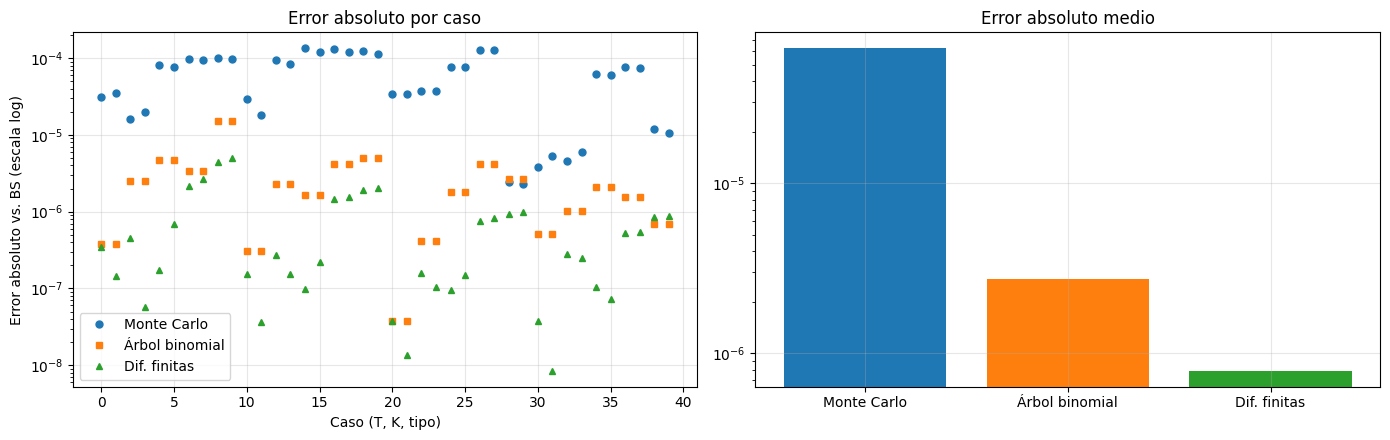

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(opt))
for col, lab, mk in [("|MC−BS|", "Monte Carlo", "o"), ("|Bin−BS|", "Árbol binomial", "s"), ("|DF−BS|", "Dif. finitas", "^")]:
    ax[0].semilogy(x, opt[col].clip(lower=1e-12), mk, label=lab, ms=5)
ax[0].set_xlabel("Caso (T, K, tipo)"); ax[0].set_ylabel("Error absoluto vs. BS (escala log)")
ax[0].set_title("Error absoluto por caso"); ax[0].legend()
ax[1].bar(["Monte Carlo", "Árbol binomial", "Dif. finitas"], [opt["|MC−BS|"].mean(), opt["|Bin−BS|"].mean(), opt["|DF−BS|"].mean()], color=["tab:blue", "tab:orange", "tab:green"])
ax[1].set_yscale("log"); ax[1].set_title("Error absoluto medio")
plt.tight_layout(); plt.show()

### Convergencia (opción ATM, T = 1, call)

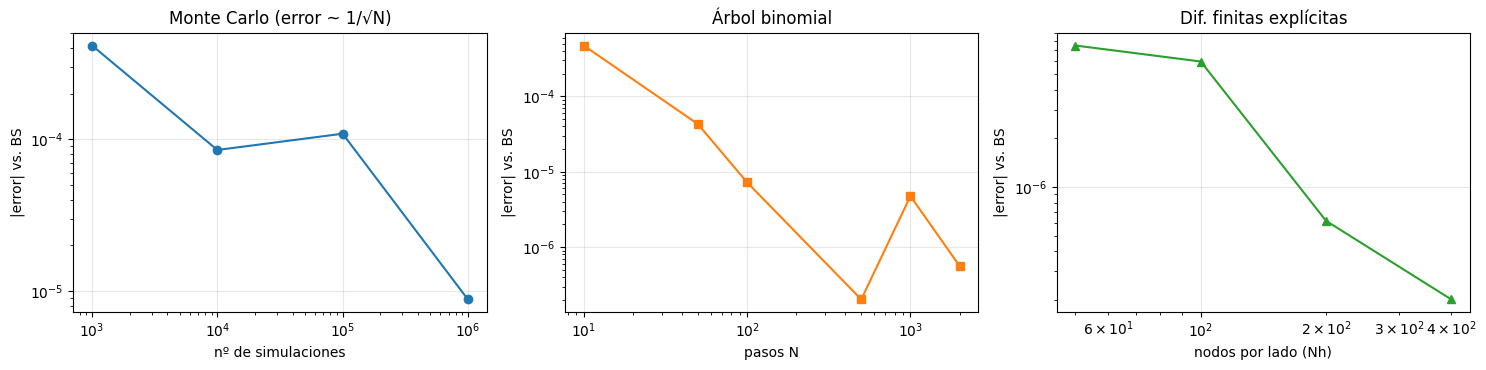

Precio BS de referencia (ATM, T=1, K=1.4142): 0.058941 CAD


In [23]:
K_atm, T_c = float(strikes[1][2]), 1.0
bs_ref = bs_price(S0_last, K_atm, T_c, r_free, q_yield, sig, "call")
rng_c = np.random.default_rng(99)
Ns_mc  = [10**k for k in (3, 4, 5, 6)]
Ns_bin = [10, 50, 100, 500, 1000, 2000]
Nh_fd  = [50, 100, 200, 400]

err_mc  = [abs(mc_price(S0_last, K_atm, T_c, r_free, q_yield, sig, rng_c.standard_normal(N // 2), "call")[0] - bs_ref) for N in Ns_mc]
err_bin = [abs(binomial_crr(S0_last, K_atm, T_c, r_free, q_yield, sig, "call", N=N) - bs_ref) for N in Ns_bin]
err_fd  = [abs(fd_explicit(S0_last, K_atm, T_c, r_free, q_yield, sig, "call", Nh=h)[0] - bs_ref) for h in Nh_fd]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].loglog(Ns_mc, err_mc, "o-"); ax[0].set_title("Monte Carlo (error ~ 1/√N)"); ax[0].set_xlabel("nº de simulaciones")
ax[1].loglog(Ns_bin, err_bin, "s-", color="tab:orange"); ax[1].set_title("Árbol binomial"); ax[1].set_xlabel("pasos N")
ax[2].loglog(Nh_fd, err_fd, "^-", color="tab:green"); ax[2].set_title("Dif. finitas explícitas"); ax[2].set_xlabel("nodos por lado (Nh)")
for a in ax: a.set_ylabel("|error| vs. BS")
plt.tight_layout(); plt.show()
print(f"Precio BS de referencia (ATM, T=1, K={K_atm:.4f}): {bs_ref:.6f} CAD")

In [ ]:
best = summ["Error abs. medio"].idxmin()
print(f"Método más cercano a Black-Scholes (menor error absoluto medio): {best}.")
print("• Black-Scholes es exacto bajo GBM; los demás son aproximaciones numéricas de la misma EDP / esperanza neutral al riesgo.")
print("• Monte Carlo tiene error estadístico (∝ 1/√N); árbol binomial y dif. finitas tienen error de discretización que decrece al refinar la malla.")
print("• Estos precios dependen de σ̂ (estimada de la muestra) y de r, q supuestos: la comparación valida los métodos numéricos, no el precio de mercado.")

Método más cercano a Black-Scholes (menor error absoluto medio): Dif. finitas.
• Black-Scholes es exacto bajo GBM; los demás son aproximaciones numéricas de la misma EDP / esperanza neutral al riesgo.
• Monte Carlo tiene error estadístico (∝ 1/√N); árbol binomial y dif. finitas tienen error de discretización que decrece al refinar la malla.
• Estos precios dependen de σ̂ (estimada de la muestra) y de r, q supuestos: la comparación valida los métodos numéricos, no el precio de mercado.


## Notas

- **No rechazar H0 no prueba que el supuesto sea cierto**; indica que no hay evidencia en contra con ~250 observaciones.
- Es un tipo de cambio (no paga dividendos). Los feriados de EE. UU. aparecen vacíos en FRED y se eliminan: algunos retornos abarcan 2 días de calendario.
- Sección 11: `r_free` y `q_yield` son **supuestos** (no provienen de los datos); la comparación de métodos numéricos no depende de su valor, pero sí los precios absolutos.
- Sección 11: los strikes se toman de trayectorias simuladas con el GBM real (μ̂, σ̂) y los precios se calculan bajo medida neutral al riesgo.
- La ventana es de solo ~1 año (250 obs. diarias): menos historia que las series semanales de 5 años, así que las pruebas ven menos regímenes distintos.
- La sección 8 verifica que la conclusión no dependa de la ventana temporal elegida.
- $\hat\mu$ es poco precisa (ver su error estándar); σ̂ es mucho más fiable.